In [1]:
import torch
import torch.nn as nn
from torchvision.models import resnet50


class CervicalCytologyModel:

    def __init__(self, model_path):

        self.device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        # Load exported artifact
        checkpoint = torch.load(
            model_path,
            map_location=self.device,
            weights_only=False
        )

        self.class_names = checkpoint["class_names"]
        self.image_size = checkpoint["image_size"]
        self.normalization = checkpoint["normalization"]

        # Reconstruct ResNet50 architecture
        self.model = resnet50(weights=None)

        num_features = self.model.fc.in_features

        self.model.fc = nn.Linear(
            num_features,
            checkpoint["num_classes"]
        )

        # Load trained weights
        self.model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        self.model.to(self.device)
        self.model.eval()

        print("Model loaded successfully!")
        print("Device:", self.device)
        print("Classes:", self.class_names)
        print("Image size:", self.image_size)

In [4]:


MODEL_PATH = "../artifacts/resnet50_cervical_cytology_best.pth"

model_instance = CervicalCytologyModel(MODEL_PATH)

Model loaded successfully!
Device: cpu
Classes: ['ASCUS', 'HSIL', 'LSIL', 'SCC', 'NILM']
Image size: 512


In [11]:
from PIL import Image

class ResizeWithPadding:

    def __init__(self, size):
        self.size = size

    def __call__(self, image):

        original_width, original_height = image.size

        scale = min(
            self.size / original_width,
            self.size / original_height
        )

        new_width = int(original_width * scale)
        new_height = int(original_height * scale)

        resized_image = image.resize(
            (new_width, new_height),
            Image.Resampling.BILINEAR
        )

        new_image = Image.new(
            "RGB",
            (self.size, self.size),
            (0, 0, 0)
        )

        paste_x = (self.size - new_width) // 2
        paste_y = (self.size - new_height) // 2

        new_image.paste(
            resized_image,
            (paste_x, paste_y)
        )

        return new_image

In [12]:
def predict_image(model_instance, image_path):

    # Preprocessing
    preprocess = transforms.Compose([
        ResizeWithPadding(512),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Transform image
    image_tensor = preprocess(image).unsqueeze(0)

    image_tensor = image_tensor.to(model_instance.device)

    # Model inference
    model_instance.model.eval()

    with torch.no_grad():
        outputs = model_instance.model(image_tensor)

        probabilities = torch.softmax(outputs, dim=1)

        confidence, predicted_class = torch.max(
            probabilities, dim=1
        )

    predicted_label = model_instance.class_names[
        predicted_class.item()
    ]

    return {
        "predicted_class": predicted_label,
        "confidence": round(confidence.item() * 100, 2)
    }

Actual class: HSIL
Selected image: ../data/processed/cleaned_data\HSIL\HSIL_233.jpg
Actual class: HSIL
Predicted class: NILM
Confidence: 56.03 %


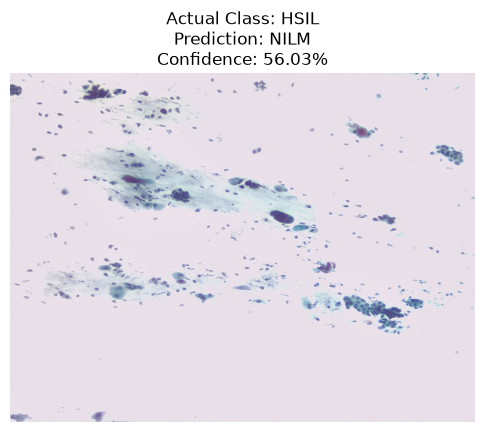

In [49]:
import os
import random

DATASET_DIR = "../data/processed/cleaned_data"

class_names = ["ASCUS", "HSIL", "LSIL", "SCC", "NILM"]

# Randomly select a class
selected_class = random.choice(class_names)

# Get images from selected class
class_dir = os.path.join(DATASET_DIR, selected_class)

image_files = [
    f for f in os.listdir(class_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Randomly select an image
selected_image = random.choice(image_files)

image_path = os.path.join(class_dir, selected_image)

print("Actual class:", selected_class)
print("Selected image:", image_path)

result = predict_image(model_instance, image_path)

print("Actual class:", selected_class)
print("Predicted class:", result["predicted_class"])
print("Confidence:", result["confidence"], "%")

import matplotlib.pyplot as plt

image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(
    f"Actual Class: {selected_class}\n"
    f"Prediction: {result['predicted_class']}\n"
    f"Confidence: {result['confidence']}%"
)
plt.show()

There are certain misclassifications that the model is performing. However there is always some chance of overfitting, so we must be careful.